In [1]:
from azure.cognitiveservices.vision.computervision import ComputerVisionClient
from azure.cognitiveservices.vision.computervision.models import OperationStatusCodes
from azure.cognitiveservices.vision.computervision.models import VisualFeatureTypes
from msrest.authentication import CognitiveServicesCredentials
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from array import array
import sys
import time
from PIL import Image
import os
import matplotlib.pyplot as plt
from skimage import io
import numpy as np


'''
Authenticate
Authenticates your credentials and creates a client.
'''
subscription_key = "DDSKJoNuiIOS14PRv1QH0KR5oGYxYKjuEOVFrD3Sk8AJGEZh207aJQQJ99BCAC5RqLJXJ3w3AAAFACOG0EZm"
endpoint = "https://resourcebibi.cognitiveservices.azure.com/"
computervision_client = ComputerVisionClient(endpoint, CognitiveServicesCredentials(subscription_key))
'''
END - Authenticate
'''

computed_results = {}


folder_path = "C:/Users/Next/Desktop/AI/AI Lab4/images"
images = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith((".png", ".jpg", ".jpeg")):
        image_path = os.path.join(folder_path, filename)
        img = open(image_path, "rb")
        images.append((img, "\"" + filename + "\""))

for processed_image, image_path in images:
    result = computervision_client.analyze_image_in_stream(processed_image, visual_features=[VisualFeatureTypes.tags, VisualFeatureTypes.objects])
    computed_results[image_path] = False
    for objc in result.objects:
        if objc.object_property.lower() == "bicycle":
            print("Bike detected: ")
            computed_results[image_path] = True




Bike detected: 
Bike detected: 
Bike detected: 
Bike detected: 
Bike detected: 
Bike detected: 
Bike detected: 
Bike detected: 
Bike detected: 


In [2]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

print(computed_results)

ground_truth = {
    "animals.png": False,
    "bike02.jpg": True,
    "bike03.jpg": True,
    "bike04.jpg": True,
    "bike05.jpg": True,
    "bike06.jpg": True,
    "bike07.jpg": True,
    "bike08.jpg": True,
    "bike09.jpg": True,
    "bike1.jpg": True,
    "bike10.jpg": True,
    "binClass.png": False,
    "IoU.png": False,
    "IoU2.png": False,
    "objectDetection.png": False,
    "people.jpg": False,
    "traffic01.jpg": False,
    "traffic02.jpg": False,
    "traffic03.jpg": False,
    "traffic04.jpg": False,
}

realLabels = []
computedLabels = []

for key, value in ground_truth.items():
    realLabels.append(value)

for key, value in computed_results.items():
    computedLabels.append(value)

print(realLabels)
print(computedLabels)


# version 1 - sklearn functions
def evalClassificationV1(realLabels, computedLabels, labelNames):
    from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

    cm = confusion_matrix(realLabels, computedLabels, labels = labelNames)
    acc = accuracy_score(realLabels, computedLabels)
    precision = precision_score(realLabels, computedLabels, average = None, labels = labelNames)
    recall = recall_score(realLabels, computedLabels, average = None, labels = labelNames)
    return acc, precision, recall

# version 2 - native code
def evalClassificationV2(realLabels, computedLabels, pos, neg):
    # noCorrect = 0
    # for i in range(0, len(realLabels)):
    #     if (realLabels[i] == computedLabels[i]):
    #         noCorrect += 1
    # acc = noCorrect / len(realLabels)
    acc = sum([1 if realLabels[i] == computedLabels[i] else 0 for i in range(0, len(realLabels))]) / len(realLabels)

    # TP = 0
    # for i in range(0, len(realLabels)):
    #     if (realLabels[i] == 'spam' and computedLabels[i] == 'spam'):
    #         TP += 1
    TP = sum([1 if (realLabels[i] == pos and computedLabels[i] == pos) else 0 for i in range(len(realLabels))])
    FP = sum([1 if (realLabels[i] == neg and computedLabels[i] == pos) else 0  for i in range(len(realLabels))])
    TN = sum([1 if (realLabels[i] == neg and computedLabels[i] == neg) else 0 for i in range(len(realLabels))])
    FN = sum([1 if (realLabels[i] == pos and computedLabels[i] == neg) else 0  for i in range(len(realLabels))])

    precisionPos = TP / (TP + FP)
    recallPos = TP / (TP + FN)
    precisionNeg = TN / (TN + FN)
    recallNeg = TN / (TN + FP)

    return acc, precisionPos, precisionNeg, recallPos, recallNeg

accV1, prec, recall = evalClassificationV1(realLabels, computedLabels, [True, False])

accV2, precPositive, precNegative, recallPositive, recallNegative = evalClassificationV2(realLabels, computedLabels, True, False)

print('acc: ', accV1, ' precision: ', prec, ' recall: ', recall)

print('acc: ', accV2, 'precPos: ', precPositive, 'precNegative: ', precNegative, 'recallPos: ', recallPositive, 'recallNegative: ', recallNegative)


{'"animals.png"': False, '"bike02.jpg"': True, '"bike03.jpg"': True, '"bike04.jpg"': True, '"bike05.jpg"': True, '"bike06.jpg"': False, '"bike07.jpg"': True, '"bike08.jpg"': False, '"bike09.jpg"': True, '"bike1.jpg"': True, '"bike10.jpg"': True, '"binClass.png"': True, '"IoU.png"': False, '"IoU2.png"': False, '"objectDetection.png"': False, '"people.jpg"': False, '"traffic01.jpg"': False, '"traffic02.jpg"': False, '"traffic03.jpg"': False, '"traffic04.jpg"': False}
[False, True, True, True, True, True, True, True, True, True, True, False, False, False, False, False, False, False, False, False]
[False, True, True, True, True, False, True, False, True, True, True, True, False, False, False, False, False, False, False, False]
acc:  0.85  precision:  [0.88888889 0.81818182]  recall:  [0.8 0.9]
acc:  0.85 precPos:  0.8888888888888888 precNegative:  0.8181818181818182 recallPos:  0.8 recallNegative:  0.9


Converted coordinates (absolute): 16.0, 89.0, 365.0, 325.0


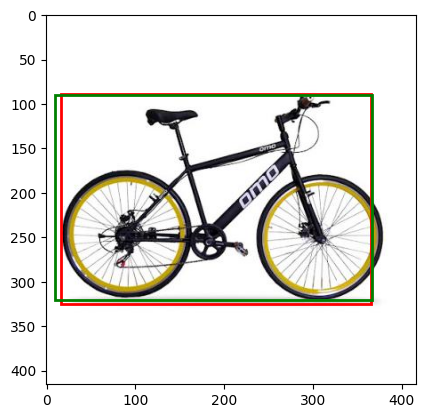

Converted coordinates (absolute): 156.0, 145.0, 340.0, 400.0


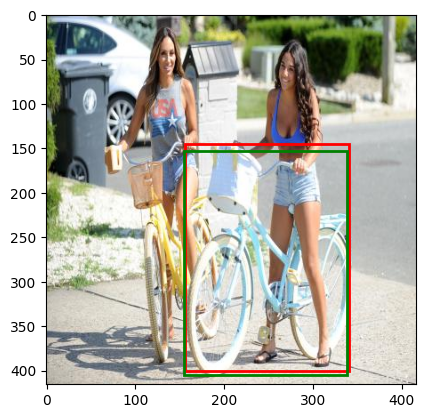

Converted coordinates (absolute): 1.0, 1.0, 413.0, 412.0


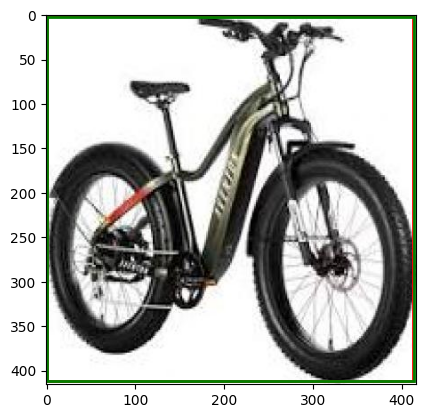

Converted coordinates (absolute): 69.0, 52.0, 360.0, 340.0


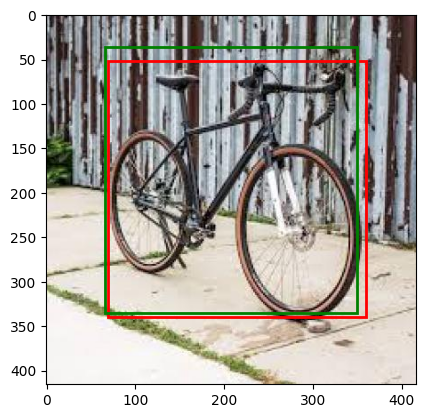

Converted coordinates (absolute): 156.0, 145.0, 340.0, 400.0


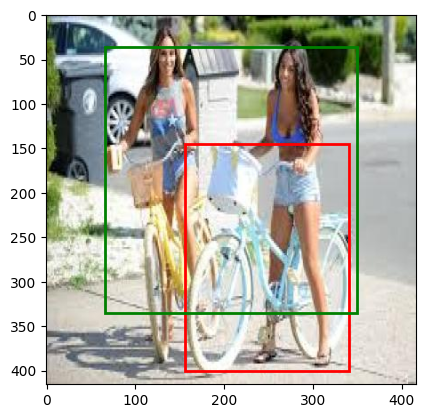

Converted coordinates (absolute): 57.0, 202.0, 300.0, 410.0


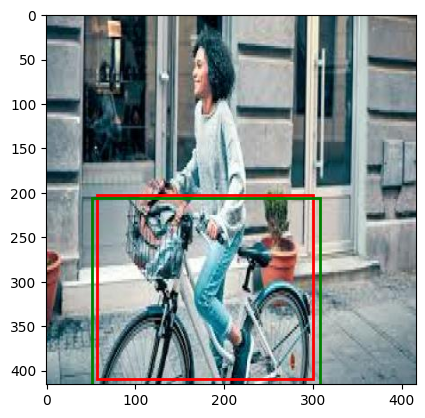

Converted coordinates (absolute): 52.0, 1.0, 390.0, 355.0


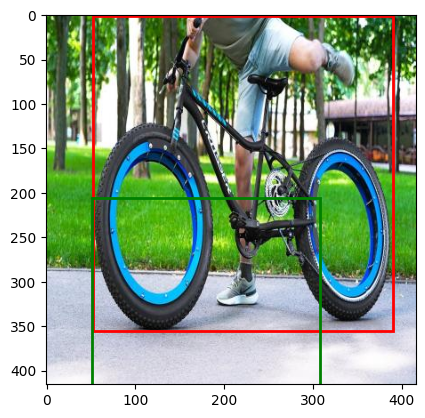

Converted coordinates (absolute): 7.0, 7.0, 374.0, 401.0


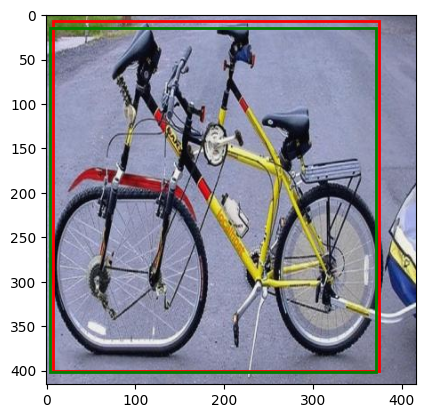

Converted coordinates (absolute): 2.0, 31.0, 408.0, 400.0


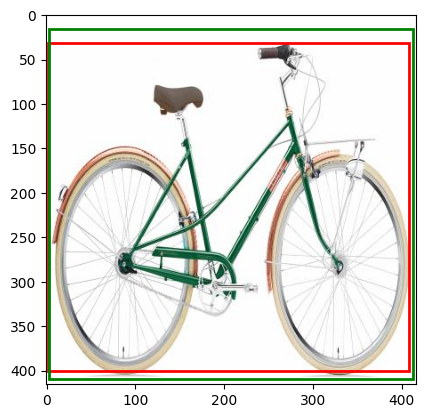

Converted coordinates (absolute): 142.0, 121.0, 390.0, 390.0


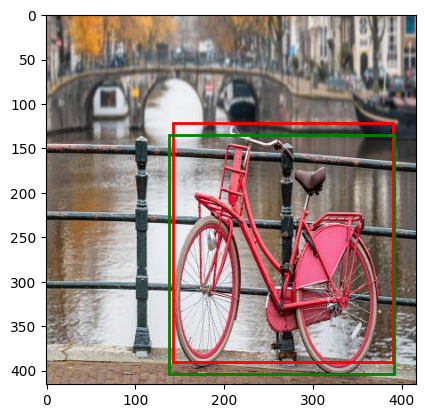

In [4]:
folder_path = "C:/Users/Next/Desktop/AI/AI Lab4/images"
images_bikes = []

for filename in os.listdir(folder_path):
    if filename.lower().__contains__("bike"):
        image_path = os.path.join(folder_path, filename)
        img = open(image_path, "rb")
        images_bikes.append((img, image_path))


coordonate_corecte = []
coordonate_detectate = []

# automatically identify the object location
for imagine, filename in images_bikes:
    result = computervision_client.analyze_image_in_stream(imagine, visual_features=[VisualFeatureTypes.objects])
    for ob in result.objects:
        if ob.object_property == "bicycle":
            predicted_bicycle = [ob.rectangle.x, ob.rectangle.y, ob.rectangle.x + ob.rectangle.w, ob.rectangle.y + ob.rectangle.h]

    im = plt.imread(filename)
    img_height, img_width, _ = im.shape
    fig = plt.imshow(im)

    # add manually some bounding boxes for each object
    annotation_path = filename.replace(".jpg", ".txt")
    annotation_path = annotation_path.replace("images", "bike_annotations")
    with open(annotation_path, "r") as file:
        line = file.readline()
    bike_coordinates = line.split(" ")
    bike_coordinates = [float(e) for e in bike_coordinates]

    # Conversia coordonatelor relative în coordonate absolute (în pixeli)
    x_min = bike_coordinates[0]
    y_min = bike_coordinates[1]
    x_max = bike_coordinates[2]
    y_max = bike_coordinates[3]

    # Afișează coordonatele convertite
    print(f"Converted coordinates (absolute): {x_min}, {y_min}, {x_max}, {y_max}")

    # Desenarea chenarelor roșii
    fig.axes.add_patch(plt.Rectangle(
        xy=(x_min, y_min),
        width=x_max - x_min,
        height=y_max - y_min,
        fill=False, color="red", linewidth=2))


    fig.axes.add_patch(plt.Rectangle(xy = (predicted_bicycle[0], predicted_bicycle[1]), width =predicted_bicycle[2] - predicted_bicycle[0], height =predicted_bicycle[3] - predicted_bicycle[1], fill = False, color ="green", linewidth = 2))

    coordonate_corecte.extend(bike_coordinates)
    coordonate_detectate.extend(predicted_bicycle)

    plt.show()



In [5]:
from math import sqrt

# MAE (Mean Absolute Error) -> medie a distanței absolute
errorL1 = sum(abs(r - c) for r, c in zip(coordonate_corecte, coordonate_detectate)) / len(coordonate_corecte)
print('Error (L1): ', errorL1)

# RMSE (Root Mean Squared Error) -> penalizează erorile mari mai mult decât cele mici
errorL2 = sqrt(sum((r - c) ** 2 for r, c in zip(coordonate_corecte, coordonate_detectate)) / len(coordonate_corecte))
print('Error (L2): ', errorL2)


print(coordonate_corecte)
print(coordonate_detectate)


coord_bune = []
coord_detectate = []
i = 0
while i < len(coordonate_corecte):
    coord_bune.append([coordonate_corecte[i], coordonate_corecte[i+1], coordonate_corecte[i+2], coordonate_corecte[i+3]])
    coord_detectate.append([coordonate_detectate[i], coordonate_detectate[i+1], coordonate_detectate[i+2], coordonate_detectate[i+3]])
    i += 4


def calculate_iou(coord1, coord2):
    x_min1, y_min1, x_max1, y_max1 = coord1
    x_min2, y_min2, x_max2, y_max2 = coord2

    # coordonatele intersecției
    x_min_intersection = max(x_min1, x_min2)
    y_min_intersection = max(y_min1, y_min2)
    x_max_intersection = min(x_max1, x_max2)
    y_max_intersection = min(y_max1, y_max2)

    if x_min_intersection < x_max_intersection and y_min_intersection < y_max_intersection:
        intersection_area = (x_max_intersection - x_min_intersection) * (y_max_intersection - y_min_intersection)
    else:
        intersection_area = 0

    area1 = (x_max1 - x_min1) * (y_max1 - y_min1)
    area2 = (x_max2 - x_min2) * (y_max2 - y_min2)

    union_area = area1 + area2 - intersection_area

    iou = intersection_area / union_area if union_area != 0 else 0

    return iou



for coord_correct, coord_detected in zip(coord_bune, coord_detectate):
    iou = calculate_iou(coord_correct, coord_detected)
    print(f"IoU :{iou:.4f}")


Error (L1):  19.75
Error (L2):  44.24477370266459
[16.0, 89.0, 365.0, 325.0, 156.0, 145.0, 340.0, 400.0, 1.0, 1.0, 413.0, 412.0, 69.0, 52.0, 360.0, 340.0, 156.0, 145.0, 340.0, 400.0, 57.0, 202.0, 300.0, 410.0, 52.0, 1.0, 390.0, 355.0, 7.0, 7.0, 374.0, 401.0, 2.0, 31.0, 408.0, 400.0, 142.0, 121.0, 390.0, 390.0]
[9, 90, 366, 321, 155, 153, 338, 405, 0, 2, 414, 412, 66, 36, 349, 335, 66, 36, 349, 335, 51, 206, 308, 416, 51, 206, 308, 416, 4, 14, 371, 402, 3, 16, 412, 410, 138, 135, 391, 404]
IoU :0.9573
IoU :0.9349
IoU :0.9928
IoU :0.8885
IoU :0.3620
IoU :0.9023
IoU :0.2816
IoU :0.9640
IoU :0.9253
IoU :0.8841
